# Theoretical Framework

## Biot - Savart Law

$$
B(r) = \frac{\mu_{0} }{4 \pi} \int{ \frac{ I \partial l \times (r - l)}{(r - l)^{3}} } = \frac{\mu_{0} }{4 \pi} \int{\int{\int_{V}{ \frac{ J(r^{\prime}) \partial V \times (r - r^{\prime})}{(r - r^{\prime})^{3}} }}}
$$

$$
B = \nabla \times A
$$

$$
A = \frac{\mu_{0}}{4 \pi} \int_{R}{ \frac{ J(r^{\prime}) }{r - r^{\prime}} \partial^{3} r^{\prime}}
$$

$$
\nabla^{2} A = - \mu_{0} J
$$


$$
B = \frac{\mu_{0} n I}{2 \pi r} = 12 \frac{\mu_{0} n I b h}{4 \pi r^{3}} 
$$


## Steady Ideal MHD

$$
\nabla \cdot ( \rho v) = 0
$$

$$
\nabla \cdot B = 0
$$

$$
\nabla \times B = \mu_{0} J
$$

In [5]:
import numpy as np
#import cupy as cp
#import random
import matplotlib.pyplot as plt
#from numba import njit, prange
import astropy.units as u
import astropy.constants as const
#from scipy.ndimage import rotate
#import pandas as pd
#from mpl_toolkits.mplot3d import Axes3D
#from mpl_toolkits.mplot3d.art3d import Line3DCollection
#from scipy.optimize import curve_fit
#from scipy.interpolate import CubicSpline, PchipInterpolator
#from tqdm import tqdm
#from matplotlib import cm
#from matplotlib.colors import Normalize
#from matplotlib.colors import LogNorm
#from scipy.integrate import solve_ivp
import gc

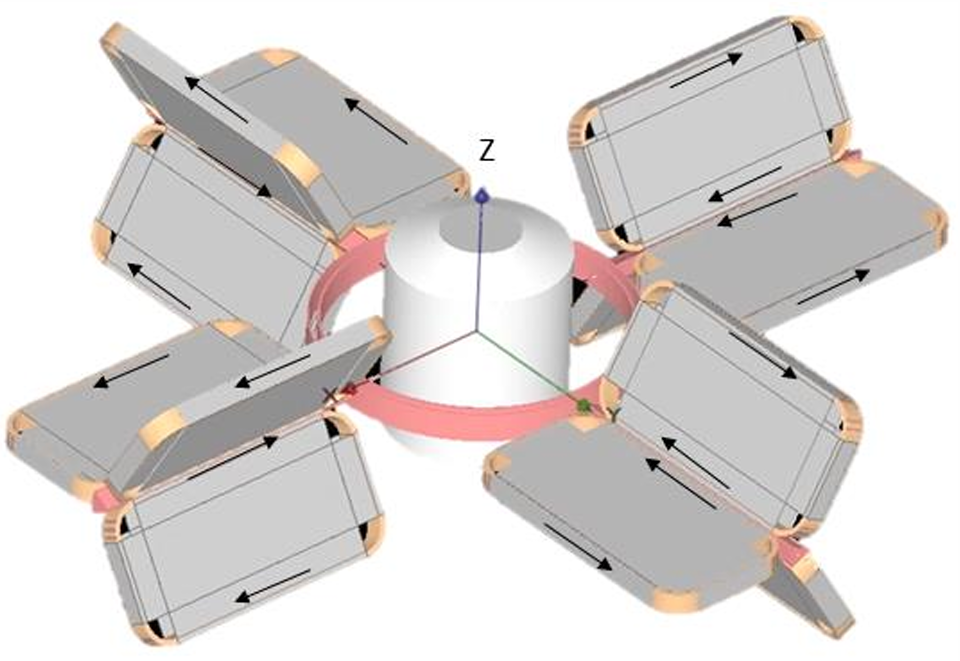

In [37]:
R = R_s[opt_mask][0].to(u.m).value
H = H_s[opt_mask][0].to(u.m).value
t = w_tape.to(u.m).value
J0 = j_s[opt_mask][0].to(u.A / u.m**2).value
ohm = rho_ohm_s[opt_mask][0].to(u.Ohm * u.m).value
R, H, t, J0, ohm

(np.float64(0.054982829769473864),
 np.float64(0.0939047619047619),
 np.float64(0.004),
 np.float64(67887931.03448276),
 np.float64(8.360462334643535e-13))

In [ ]:
W = 3 * u.m
L = 7.5 * u.m


In [3]:
0.05 * 1e3

50.0

In [44]:
(12 * Vol_inf_s[opt_mask] * density_tape).to(u.kg)

<Quantity [6.23680592] kg>

In [48]:
J0 * u.A / u.m**2 * A_tape

<Quantity 25. A>

In [49]:
keep = {'R', 'H', 't', 'J0', 'ohm',
        'np', 'const', 'u', 'plt', 'prange', 'rotate', 'gc', 'tqdm'}  # variables que quieres mantener

for name in list(globals().keys()):
    if name not in keep and not name.startswith("_"):
        del globals()[name]

gc.collect()

18929

In [50]:
mu0 = const.mu0.to(u.N / u.A**2).value
v_sw = (1e3 * u.km / u.s).to(u.m / u.s).value
rho_sw = (10 / u.cm**3).to(1 / u.m**3).value
P_sw = (6 * u.nPa).to(u.Pa).value
B_sw = (10 * u.nT).to(u.T).value
gamma_sw = 5 / 3
m_p = const.m_p.to(u.kg).value
q_p = const.e.to(u.C).value

mu0, v_sw, rho_sw, P_sw, B_sw, gamma_sw, m_p, q_p

(np.float64(1.25663706127e-06),
 np.float64(1000000.0),
 np.float64(9999999.999999998),
 np.float64(6.000000000000001e-09),
 np.float64(1e-08),
 1.6666666666666667,
 np.float64(1.67262192595e-27),
 np.float64(1.602176634e-19))

In [52]:
L_shield = 0.1 # m 
#B_shield = 4.5*1e-3 # T

Lx = 10 * L_shield # m
Ly = 10 * L_shield # m
Lz = 10 * L_shield # m

h = t.copy()# 5e-3
Co = 0.1
tol = 1e-9
max_iter = 1000

dt = Co * h / v_sw

Nx = np.ceil(Lx / h + 1).astype(int)
Ny = np.ceil(Ly / h + 1).astype(int)
Nz = np.ceil(Lz / h + 1).astype(int)

k_sor = 2 / (1 + np.sin(np.pi / np.max([Nx, Ny, Nz])))

dt, Nx, Ny, Nz, k_sor

(np.float64(4e-10),
 np.int64(251),
 np.int64(251),
 np.int64(251),
 np.float64(1.9752774694651012))

In [53]:
xs = np.linspace(-Lx/2, Lx/2, Nx)
ys = np.linspace(-Ly/2, Ly/2, Nx)
zs = np.linspace(-Lz/2, Lz/2, Nx)

X, Y, Z = np.meshgrid(xs, ys, zs, indexing="ij")
X.shape

(251, 251, 251)

In [54]:
"""
def cylinder(Field, value, axis, P_axi, P_rad, f_axi, f_rad, r_axi, r_rad):
    F = Field.copy()
    mask = (
    (np.hypot(P_rad[0] - f_rad[0], P_rad[1] - f_rad[1]) < r_rad + h)
    &
    (np.abs(P_axi - f_axi) < r_axi + h) 
    )
    F[..., axis][mask] = value
    return F
"""
def cylinder(Field, value, axis_axi, axis_rad, P_axi, P_rad, height, radius, thickness):

    radial = P_rad[0]**2 + P_rad[1]**2
    cylinder = (radial >= (radius - 0.5*thickness)**2) & (radial <= (radius + 0.5*thickness)**2) & (np.abs(P_axi) <= height/2)
    
    T_axi = np.zeros_like(P_axi)
    T_rad0 = -P_rad[1]
    T_rad1 = P_rad[0]

    Field[..., axis_axi] = T_axi * cylinder
    Field[..., axis_rad[0]] = T_rad0 * cylinder
    Field[..., axis_rad[1]] = T_rad1 * cylinder    

    Field = value * Field / np.linalg.norm(Field, axis=-1)[...,None]
    Field[~np.isfinite(Field)] = 0
    return Field

In [55]:
Field = np.zeros((Nx, Ny, Nz, 3))

J_coil = Field.copy()
#J_coil += cylinder(Field, -J0, 0, X, (Y, Z), 0.5 * (4*L_shield + R), (0  , 0), 0.5 * R, 0.5 * H)
#J_coil += cylinder(Field, +J0, 0, X, (Y, Z), 0.5 * (4*L_shield + R), (-R, 0), 0.5 * R, 0.5 * H)
#J_coil += cylinder(Field, +J0, 1, Y, (X, Z), -0.5 * R, (0.5*4*L_shield, 0), 0.5 * R, 0.5 * H)
#J_coil += cylinder(Field, -J0, 1, Y, (X, Z), -0.5 * R, (0.5*4*L_shield + R, 0), 0.5 * R, 0.5 * H)
#J_coil = J_coil * J0 / np.linalg.norm(J_coil, axis=-1)[..., None]
#J_coil[~np.isfinite(J_coil)] = 0
phase = max( 0.5 * ( L_shield + R + 2 * t ), ( H + 0.5 * ( R + 2 * t ) ) * 2**0.5 ) + 2 * min(t, H, R, L_shield)
J_coil += cylinder(Field, J0, 2, (0, 1), Z - H, (X - phase, Y), H, R, t)
phase

/tmp/ipykernel_18539/3564326149.py:25: RuntimeWarning: invalid value encountered in divide
  Field = value * Field / np.linalg.norm(Field, axis=-1)[...,None]


np.float64(0.18533697388544357)

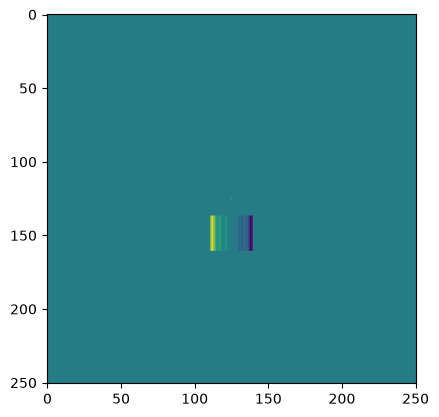

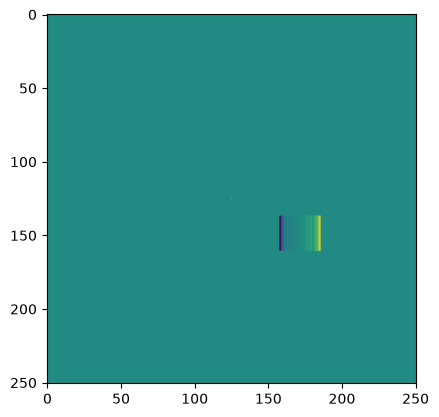

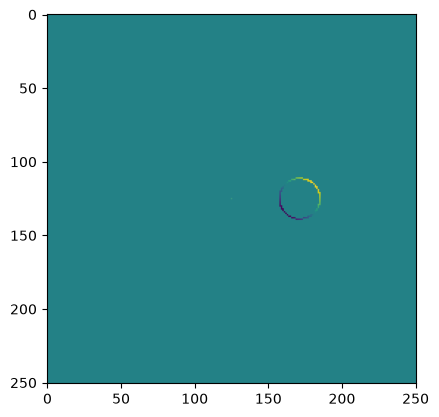

In [56]:
for i in range(3):
    plt.imshow(np.sum(J_coil, axis=(i,3)).T)
    plt.imshow(np.sum(((X==0)&(Y==0))*np.ones_like(X), axis=2), alpha=0.1)
    plt.show()

In [57]:
J_arm = Field.copy()
for i in [0, 120, 240]:
    J_arm += rotate(J_coil, angle=i, axes=(1,2), reshape=False, order=3)

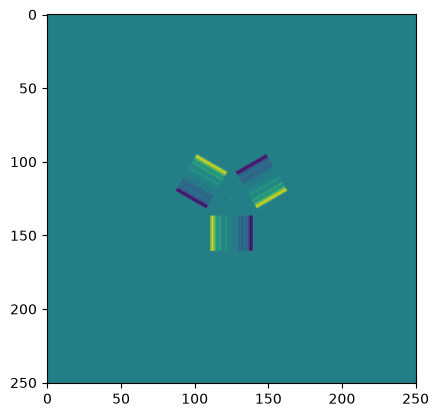

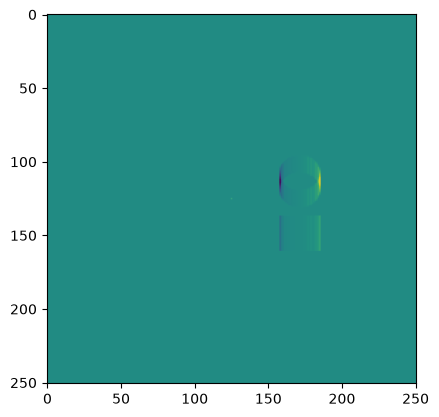

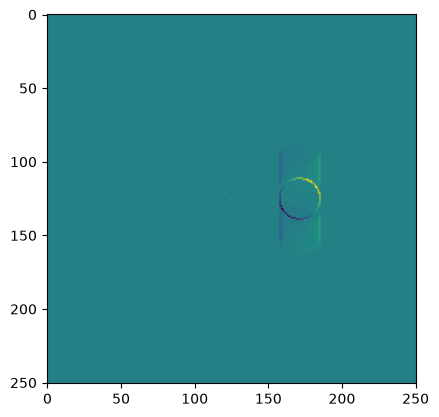

In [58]:
for i in range(3):
    plt.imshow(np.sum(J_arm, axis=(i,3)).T)
    plt.imshow(np.sum(((X==0)&(Y==0))*np.ones_like(X), axis=2), alpha=0.1)
    plt.show()

In [59]:
J_shield = Field.copy()
for i in [0, 90, 180, 270]:
    J_shield += rotate(J_arm, angle=i, axes=(0,1), reshape=False, order=3)

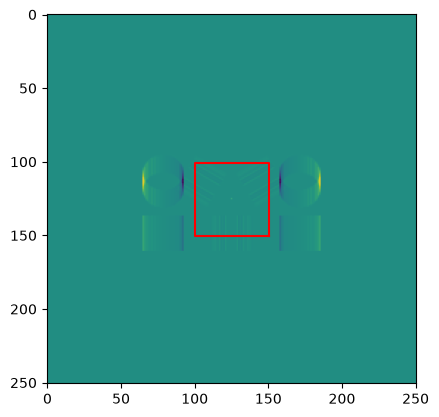

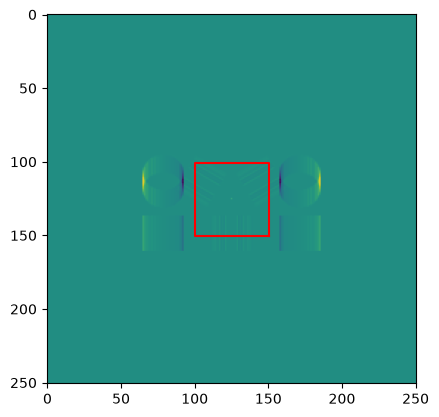

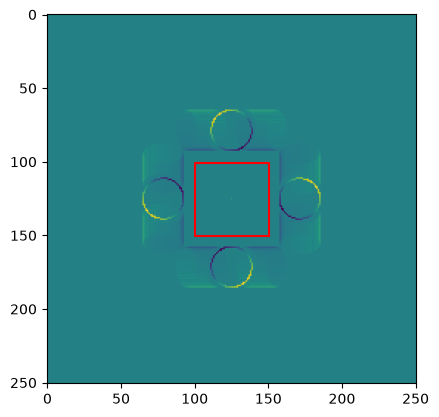

In [60]:
for i in range(3):
    plt.imshow(np.sum(J_shield, axis=(i,3)).T)
    plt.imshow(np.sum(((X==0)&(Y==0))*np.ones_like(X), axis=2), alpha=0.1)
    plt.plot(0.5*Nx + np.array([0.1,0.1,-0.1,-0.1,0.1])/h, 0.5*Nx + np.array([0.1,-0.1,-0.1,0.1,0.1])/h, c="r")
    plt.show()

In [61]:
Shield = np.linalg.norm(J_shield, axis=-1)
Shield = Shield >= (J0 - np.spacing(J0) - 6 * (Shield.std() + np.spacing(Shield.std())))

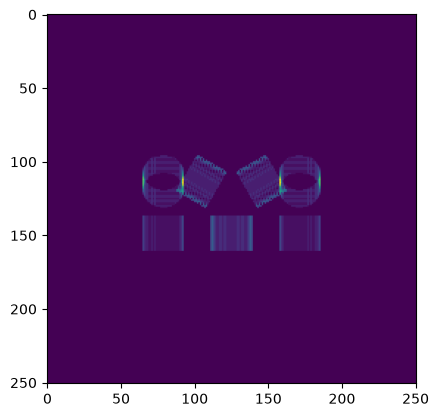

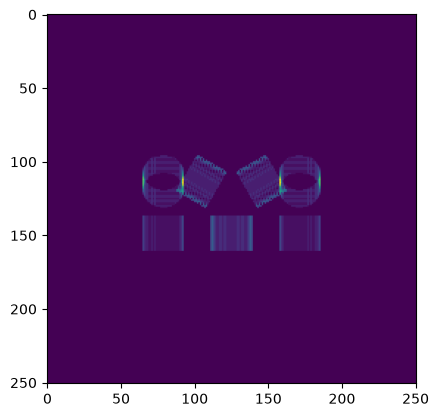

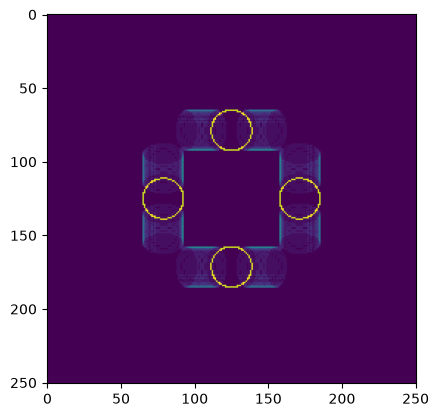

In [62]:
for i in range(3):
    plt.imshow(np.sum(Shield, axis=i).T)
    plt.show()

In [63]:
"""
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

mask_protected = (np.abs(X) <= L_shield) & (np.abs(Y) <= L_shield) & (np.abs(Z) <= L_shield)
#ax.scatter3D(X[mask_protected], Y[mask_protected], Z[mask_protected], marker=",", alpha=2e-3, c="dodgerblue", label="Protected Volume")
ax.scatter3D(X[Shield], Y[Shield], Z[Shield], marker=",", alpha=2e-3, c="navy", label="EM Shield")

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_aspect("equal")

ax.set_xlim(xs.min(), xs.max())
ax.set_ylim(ys.min(), ys.max())
ax.set_zlim(zs.min(), zs.max())

#ax.view_init(elev=60, azim=60)
plt.legend()
plt.title('Geometry')
plt.show()
"""

'\nfig = plt.figure()\nax = fig.add_subplot(projection=\'3d\')\n\nmask_protected = (np.abs(X) <= L_shield) & (np.abs(Y) <= L_shield) & (np.abs(Z) <= L_shield)\n#ax.scatter3D(X[mask_protected], Y[mask_protected], Z[mask_protected], marker=",", alpha=2e-3, c="dodgerblue", label="Protected Volume")\nax.scatter3D(X[Shield], Y[Shield], Z[Shield], marker=",", alpha=2e-3, c="navy", label="EM Shield")\n\nax.set_xlabel(\'X\')\nax.set_ylabel(\'Y\')\nax.set_zlabel(\'Z\')\nax.set_aspect("equal")\n\nax.set_xlim(xs.min(), xs.max())\nax.set_ylim(ys.min(), ys.max())\nax.set_zlim(zs.min(), zs.max())\n\n#ax.view_init(elev=60, azim=60)\nplt.legend()\nplt.title(\'Geometry\')\nplt.show()\n'

In [64]:
E_ = ohm * J_shield

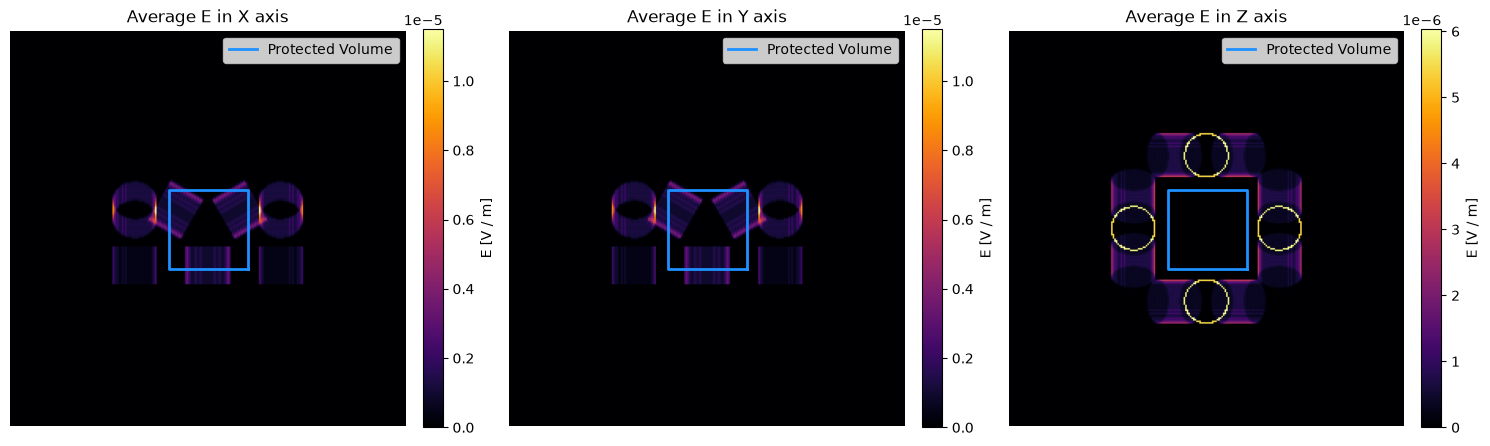

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

E_norm = np.linalg.norm(E_, axis=-1)

for i, (ax, axis_name) in enumerate(zip(axes, ["X", "Y", "Z"])):

    img = ax.imshow(
        np.mean(E_norm, axis=i).T,
        cmap="inferno"
    )

    ax.plot(
        0.5*Nx + np.array([0.1,0.1,-0.1,-0.1,0.1])/h,
        0.5*Nx + np.array([0.1,-0.1,-0.1,0.1,0.1])/h,
        c="dodgerblue",
        #alpha=0.5,
        lw=2,
        label="Protected Volume"
    )

    ax.set_title(f"Average E in {axis_name} axis")
    ax.axis("off")
    ax.legend()
    fig.colorbar(img, ax=ax, fraction=0.046, pad=0.04, label="E [V / m]")
    
plt.tight_layout()
plt.show()

In [66]:
def poisson_fft(J, mu0, h, pad_factor=0.25):
    """
    Resuelve ∇²A = -μ0 J usando FFT + padding

    Parameters
    ----------
    J : (Nx, Ny, Nz, 3) numpy array
    mu0 : float
    h : float (grid spacing)
    pad_factor : float

    Returns
    -------
    A : (Nx, Ny, Nz, 3) numpy array
    """
    Nx, Ny, Nz, _ = J.shape

    px = int(pad_factor * Nx)
    py = int(pad_factor * Ny)
    pz = int(pad_factor * Nz)

    pad_width = ((px, px), (py, py), (pz, pz), (0, 0))
    Jp = np.pad(J, pad_width, mode='constant')

    Nx_p, Ny_p, Nz_p, _ = Jp.shape

    kx = 2 * np.pi * np.fft.fftfreq(Nx_p, d=h)
    ky = 2 * np.pi * np.fft.fftfreq(Ny_p, d=h)
    kz = 2 * np.pi * np.fft.fftfreq(Nz_p, d=h)

    KX, KY, KZ = np.meshgrid(kx, ky, kz, indexing='ij')
    K2 = KX**2 + KY**2 + KZ**2
    K2[0, 0, 0] = 1.0 # evitar división por cero

    A = np.zeros_like(Jp)

    for i in tqdm(range(3)):
        J_hat = np.fft.fftn(Jp[..., i])
        A_hat = mu0 * J_hat / K2
        A_hat[0, 0, 0] = 0.0  # gauge

        A[..., i] = np.real(np.fft.ifftn(A_hat))

    A = A[
        px:px+Nx,
        py:py+Ny,
        pz:pz+Nz,
        :
    ]

    return A

In [67]:
A = poisson_fft(J_shield, mu0, h, 0.25)

100%|██████████| 3/3 [00:28<00:00,  9.62s/it]


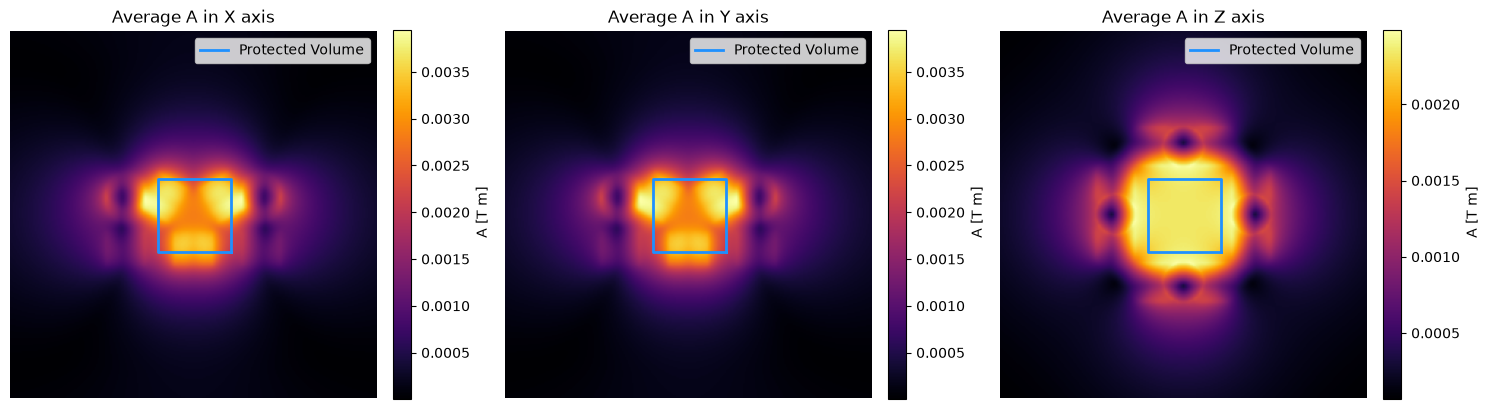

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

A_norm = np.linalg.norm(A, axis=-1)

for i, (ax, axis_name) in enumerate(zip(axes, ["X", "Y", "Z"])):

    img = ax.imshow(
        np.mean(A_norm, axis=i).T,
        cmap="inferno"
    )

    ax.plot(
        0.5*Nx + np.array([0.1,0.1,-0.1,-0.1,0.1])/h,
        0.5*Nx + np.array([0.1,-0.1,-0.1,0.1,0.1])/h,
        c="dodgerblue",
        #alpha=0.5,
        lw=2,
        label="Protected Volume"
    )

    ax.legend()
    ax.set_title(f"Average A in {axis_name} axis")
    ax.axis("off")

    fig.colorbar(img, ax=ax, fraction=0.046, pad=0.04, label=" A [T m]")

plt.tight_layout()
plt.show()

In [69]:
def rot(F, h):
    Fx, Fy, Fz = F[..., 0], F[..., 1], F[..., 2]

    dFz_dy = np.gradient(Fz, h, axis=1, edge_order=2)
    dFy_dz = np.gradient(Fy, h, axis=2, edge_order=2)

    dFx_dz = np.gradient(Fx, h, axis=2, edge_order=2)
    dFz_dx = np.gradient(Fz, h, axis=0, edge_order=2)

    dFy_dx = np.gradient(Fy, h, axis=0, edge_order=2)
    dFx_dy = np.gradient(Fx, h, axis=1, edge_order=2)

    curl = np.empty_like(F)
    curl[..., 0] = dFz_dy - dFy_dz
    curl[..., 1] = dFx_dz - dFz_dx
    curl[..., 2] = dFy_dx - dFx_dy

    return curl

In [70]:
B_ = rot(A, h)
np.linalg.norm(B_, axis=-1).max(), np.linalg.norm(B_, axis=-1).min()

(np.float64(0.3398236108969073), np.float64(5.9241056417852866e-08))

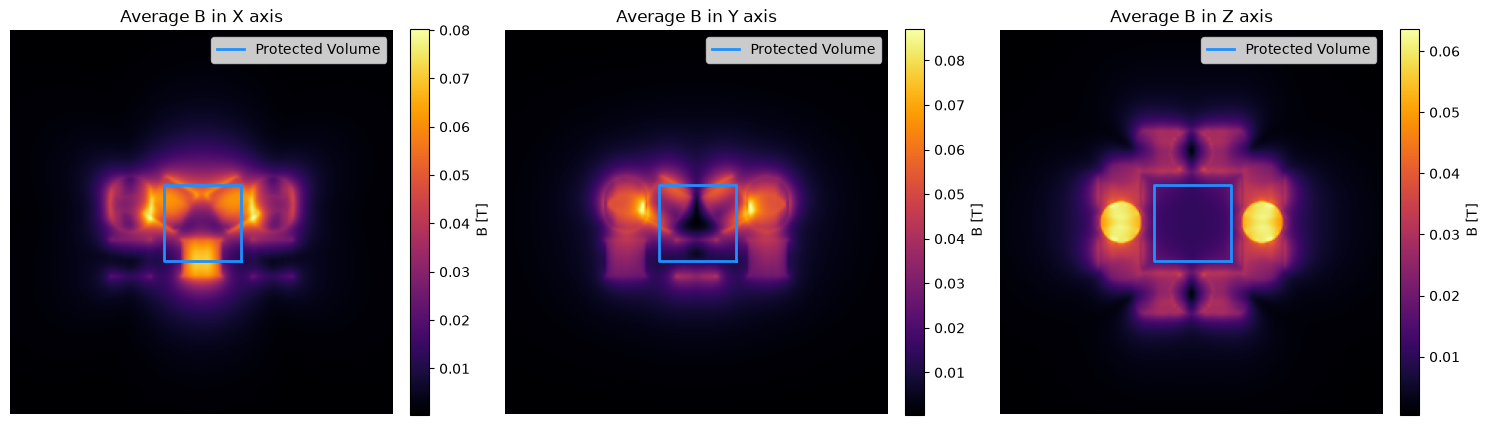

In [71]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

B_norm = np.linalg.norm(B_, axis=-1)

for i, (ax, axis_name) in enumerate(zip(axes, ["X", "Y", "Z"])):

    img = ax.imshow(
        np.mean(B_norm, axis=i).T,
        cmap="inferno"
    )

    ax.plot(
        0.5*Nx + np.array([0.1,0.1,-0.1,-0.1,0.1])/h,
        0.5*Nx + np.array([0.1,-0.1,-0.1,0.1,0.1])/h,
        c="dodgerblue",
        #alpha=0.5,
        lw=2,
        label="Protected Volume"
    )

    ax.legend()
    ax.set_title(f"Average B in {axis_name} axis")
    ax.axis("off")

    fig.colorbar(img, ax=ax, fraction=0.046, pad=0.04, label=" B [T]")

plt.tight_layout()
plt.show()

In [72]:
from scipy.interpolate import RegularGridInterpolator

Bx_interp = RegularGridInterpolator((xs, ys, zs), B_[..., 0], method="linear", bounds_error=False, fill_value=0)
By_interp = RegularGridInterpolator((xs, ys, zs), B_[..., 1], method="linear", bounds_error=False, fill_value=0)
Bz_interp = RegularGridInterpolator((xs, ys, zs), B_[..., 2], method="linear", bounds_error=False, fill_value=B_sw)


Ex_interp = RegularGridInterpolator((xs, ys, zs), E_[..., 0], method="linear", bounds_error=False, fill_value=0)
Ey_interp = RegularGridInterpolator((xs, ys, zs), E_[..., 1], method="linear", bounds_error=False, fill_value=0)
Ez_interp = RegularGridInterpolator((xs, ys, zs), E_[..., 2], method="linear", bounds_error=False, fill_value=0)

def B_interp(pos):
    return np.array([
        Bx_interp(pos),
        By_interp(pos),
        Bz_interp(pos)
    ]).T#.flatten()

def E_interp(pos):
    return np.array([
        Ex_interp(pos),
        Ey_interp(pos),
        Ez_interp(pos)
    ]).T#.flatten()

In [73]:
#plt.plot(X[(Y==0) & (Z==0)], np.linalg.norm(B_[(Y==0) & (Z==0)],axis=-1), "r-")
#plt.plot(np.linspace(xs.min()-1, xs.max()+1, 1000), np.linalg.norm(B_interp(np.array([(i,0,0) for i in np.linspace(xs.min()-1, xs.max()+1, 1000)])), axis=-1), "k:")

In [74]:
def deriv(t, y, q, m):
    r = y[:3]
    v = y[3:]
    
    B = B_interp(r)[0]
    E = E_interp(r)[0]
    
    dvdt = q / m * (E + np.cross(v, B))
    drdt = v
    
    return np.concatenate([drdt, dvdt])

In [ ]:
from scipy.integrate import solve_ivp
SOL = []

for xi in tqdm(xs[len(xs)//2::len(xs)//10][:1]):
    for yi in tqdm(ys[len(ys)//2::len(ys)//50]):

        y0 = np.array([xi, yi, 1, 0, 0, -v_sw])

        sol = solve_ivp(
            deriv,
            t_span=(0, 2 * max(Lx,Ly,Lz) / v_sw),
            #t_eval= np.linspace(0, 2/v_sw, int(1e6)),
            y0=y0,
            args=(q_p, m_p),
            method='Radau',
            #events=outside
        )
        SOL.append(sol)

#sol.y = sol.y_events[0]
#sol.t = sol.t_events[0]

sol

  0%|          | 0/1 [00:00<?, ?it/s]


NameError: name 'solve_ivp' is not defined

In [ ]:
from scipy.integrate import solve_ivp
from tqdm import tqdm

SOL = []

for xi in tqdm(xs):

    y0 = np.array([xi, 0, 1, 0, 0, -v_sw])

    sol = solve_ivp(
        deriv,
        t_span=(0, 2 * max(Lx,Ly,Lz) / v_sw),
        #t_eval= np.linspace(0, 2/v_sw, int(1e6)),
        y0=y0,
        args=(q_p, m_p),
        method='Radau',
        #events=outside
    )
    SOL.append(sol)
"""
for yi in tqdm(ys):

    y0 = np.array([0, yi, 1, 0, 0, -v_sw])

    sol = solve_ivp(
        deriv,
        t_span=(0, 2 * max(Lx,Ly,Lz) / v_sw),
        #t_eval= np.linspace(0, 2/v_sw, int(1e6)),
        y0=y0,
        args=(q_p, m_p),
        method='Radau',
        #events=outside
    )
    SOL.append(sol)
"""
#sol.y = sol.y_events[0]
#sol.t = sol.t_events[0]

In [ ]:
#plt.plot(sol.t, sol.y[0], label="x")
#plt.plot(sol.t, sol.y[1], label="y")
#plt.plot(sol.t, sol.y[2], label="z")
plt.figure(figsize=(8,4))

for sol in SOL:
    #plt.plot(sol.t, sol.y[0], label="x")
    #plt.plot(sol.t, sol.y[1], label="y")
    #plt.plot(sol.t, sol.y[2], label="z")
    plt.plot(sol.t, np.linalg.norm(sol.y[:3],axis=0), "-", c="magenta", label="r")

#plt.legend()
plt.xlabel("Time [s]")
plt.ylabel(r"$||\vec{r}||$ [m]")
plt.title("Relative position with respect to protected volume center")
#plt.yscale("asinh")
#plt.plot(sol.y[2], np.linalg.norm(sol.y[:3], axis=0), "b-")

In [ ]:
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(projection='3d')


for sol in SOL:
    ax.plot(sol.y[0], sol.y[1], sol.y[2], c="magenta")

ax.scatter3D(X[Shield], Y[Shield], Z[Shield], marker=",", alpha=5e-3, c="k")

ax.plot([0,0,0,0,0], [0.1,0.1,-0.1,-0.1,0.1], [0.1,-0.1,-0.1,0.1,0.1], c="dodgerblue", zorder=10, label="Protected Volume")

ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_zlabel('Z [m]')
#ax.set_aspect("equal")

ax.set_xlim(xs.min(), xs.max())
ax.set_ylim(ys.min(), ys.max())
ax.set_zlim(zs.min(), zs.max())

ax.view_init(elev=0, azim=0)
plt.legend()
plt.title('Solar Wind Proton Trajectory')
plt.show()

In [ ]:
def BC_F(A, value):
    A[:,0, :, :] = value[...,None,None]
    A[:,-1, :, :] = value[...,None,None]
    A[:,:, 0, :] = value[...,None,None]
    A[:,:, -1, :] = value[...,None,None]
    A[:,:, :, 0] = value[...,None,None]
    
    A[:, :, -1, :] = A[:, :, -2, :]
    return A

def BC_f(A, value):
    A[0, :, :] = value
    A[-1, :, :] = value
    A[:, 0, :] = value
    A[:, -1, :] = value
    A[:, :, 0] = value
    
    A[:, :, -1] = A[:, :, -2]
    return A

In [ ]:
def grad(f, value, h):
    BC_f(f, value)
    return np.array(np.gradient(f, h, edge_order=2))

def derivatives(F, value, h, adv=False, V=None):
    """
    F: (3, nx, ny, nz)
    returns dF[a, b] = ∂F[a] / ∂x_b
    shape: (3, 3, nx, ny, nz)
    """
    BC_F(F, value)
    dF = np.empty((3,) + F.shape, dtype=F.dtype)
    divF = np.empty(F.shape, dtype=F.dtype)
    rotF = np.empty(F.shape, dtype=F.dtype)

    for i in range(3):  # componente del campo
        dF[i] = np.gradient(F[i], h, edge_order=2)

    divF[:] = dF[0,0] + dF[1,1] + dF[2,2]

    rotF[0] = dF[2,1] - dF[1,2]
    rotF[1] = dF[0,2] - dF[2,0]
    rotF[2] = dF[1,0] - dF[0,1]

    if adv:
        advF = np.empty(F.shape, dtype=F.dtype)
        for i in range(3):
            advF[i] = V[0] * dF[i,0] + V[1] * dF[i,1] + V[2] * dF[i,2]
        return divF, rotF, advF
    else:
        return divF, rotF

In [ ]:
A = np.zeros((3, Nx, Ny, Nz))

In [ ]:
BC_F(A, np.array([-1,-1, 1]))

In [ ]:
A = np.zeros((Nx, Ny, Nz, 3))
A[:] = A__.copy()

J  = np.zeros((Nx, Ny, Nz, 3))
J[:] = J_shield.copy()

B  = np.zeros((Nx, Ny, Nz, 3))
B[:] = B_
B[:,:,:,2] += B_sw

v  = np.zeros((Nx, Ny, Nz, 3))
v[:,:,:,2] = v_sw 

rho  = np.zeros((Nx, Ny, Nz))
rho[:] = rho_sw

P  = np.zeros((Nx, Ny, Nz))
P[:] = P_sw

A_ = A.copy()
rho_ = rho.copy()

e = 1 + tol
r = 1 + tol
eiter = 0
riter = 0
print(riter, eiter, r, e, dt)
while (((r > tol) or (riter < 2)) and (riter < max_iter)):
    e = 1 + tol
    eiter = 0
    while (((e > tol) or (eiter < 2)) and (eiter < max_iter)):
        #k_sor_ = k_sor = 1 if random.getrandbits(1) else 1
        A[:] = Poisson(A_, mu0 * J / h**2, k_sor)
        A = BC_A(A)
        #A = BC_neumann_F(A)
        e = np.max(np.abs(A - A_))
        A_[:] = A
        if eiter%1000 == 0:
            print(e)
        eiter += 1

    B[:] = rot(A, h)
    B = BC_robin_F(B, B_sw)

    v += dt * ((np.cross(J, B, axis=-1)/rho[..., None] - grad(P/rho , h))  - adv(v, h))
    v = BC_robin_F(v, v_sw)
    v[Shield] = 0
    #print(v.min(), v.max())

    rho -= dt * div(rho, v, h)
    rho = BC_robin_f(rho, rho_sw)
    rho[Shield] = rho_sw
    rho[rho <= 0] = rho_sw
    #print(rho.min(), rho.max())

    P[:] = rho**gamma_sw * P_sw / rho_sw**gamma_sw
    P = BC_robin_f(P, P_sw)

    B += dt * rot(np.cross(v, B, axis=-1), h)
    B = BC_robin_F(B, B_sw)
    #print(np.max(np.abs(rot(np.cross(v, B, axis=-1), h))))

    J[:] = rot(B, h) / mu0
    J = BC_robin_F(J, 0)
    J[Shield] = J_shield[Shield]

    dt_Co = Co * h / np.nanmax(np.linalg.norm(v, axis=-1))
    r = np.max(np.abs(rho - rho_))
    rho_[:] = rho
    riter += 1
    print(riter, eiter, r, e, dt, dt_Co)

In [ ]:
import numpy as np
import time
from scipy.ndimage import convolve1d
from numba import njit, prange

# 1. IMPLEMENTACIÓN OPTIMIZADA CON CONVOLUCIÓN (SciPy)
def laplacian_scipy(u, h_inv_sq):
    k = np.array([1, -2, 1]) * h_inv_sq
    # Suma de tres convoluciones 1D separables
    lap = convolve1d(u, k, axis=0)
    lap += convolve1d(u, k, axis=1)
    lap += convolve1d(u, k, axis=2)
    return lap

# 2. IMPLEMENTACIÓN OPTIMIZADA CON NUMBA (Parallel JIT)
@njit(parallel=True, fastmath=True)
def laplacian_numba(u, h_inv_sq):
    nx, ny, nz = u.shape
    lap = np.empty_like(u)
    
    # prange distribuye las iteraciones entre los núcleos de la CPU
    for i in prange(1, nx - 1):
        for j in range(1, ny - 1):
            for k in range(1, nz - 1):
                lap[i, j, k] = (
                    u[i+1, j, k] + u[i-1, j, k] +
                    u[i, j+1, k] + u[i, j-1, k] +
                    u[i, j, k+1] + u[i, j-1, k] - 6.0 * u[i, j, k]
                ) * h_inv_sq
    return lap

# Configuración del test
N = 200
data = np.random.rand(N, N, N).astype(np.float64)
h_inv_sq = 1.0 / (0.1**2)

In [ ]:
%%timeit -n 10 -r 100
_ = laplacian_numba(data, h_inv_sq)

In [ ]:
%%timeit -n 10 -r 100
_ = laplacian_scipy(data, h_inv_sq)

In [ ]:
%%timeit
res_numba = laplacian_numba(data, h_inv_sq)